# Cleaning and Normalizing the IMDb Movies by Year Dataset

This notebook takes the combined file built by the guide notebook, `imdb_movies_1920_2026.csv` (106,999 films, 98 columns), and turns it into a clean dataset. It runs in about seven minutes.

**Outline**

1. **Setup:** libraries, chart style, helper functions and loading the data.
2. **Analysis for the reductions:** which columns and films carry no information or fall outside the dataset.
3. **Reductions:** remove those films and columns.
4. **Field groups, one by one:** text, label lists, certificate, release dates, money, ratings and awards, credits. Each section shows what is wrong, fixes it and shows the result.
5. **Types and size:** why the files are as big as they are, and the final types.
6. **Overview:** quality checks, before and after, and how complete the clean data is.
7. **Export:** the clean files in `/kaggle/working`.

| Output file | Contents |
| --- | --- |
| `imdb_movies_1920_2026_clean.parquet` | The clean table with its types. Lists and records are nested columns. |
| `imdb_movies_1920_2026_clean.csv` | The same table as text. Lists are JSON arrays; each record is a JSON array of its fields, in the order the dictionary gives. |
| `imdb_movies_1920_2026_clean_dictionary.csv` | Every column with its type and description. |

<h3 style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; color: #2c3e50; margin-top: 40px;">Contact Me</h3>

<p style="font-size: 16px; color: #555;">
  If you notice anything lacking, spot an issue with this notebook, or have suggestions for improvements, feel free to reach out through any of the platforms below:
</p>

<table style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; border-collapse: collapse; width: 100%; max-width: 600px;">
  <tbody>
    <tr>
      <td style="padding: 10px;">
        <a href="https://raedaddala.github.io/" target="_blank">
          <img src="https://img.shields.io/badge/Website-raedaddala.github.io-222222?style=for-the-badge&logo=githubpages" alt="Website Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://www.linkedin.com/in/addalaraed/" target="_blank">
          <img src="https://img.shields.io/badge/LinkedIn-Raed_Addala-blue?style=for-the-badge&logo=linkedin" alt="LinkedIn Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://www.researchgate.net/profile/Raed-Addala" target="_blank">
          <img src="https://img.shields.io/badge/ResearchGate-Raed_Addala-00CCBB?style=for-the-badge&logo=researchgate&logoColor=white" alt="ResearchGate Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://x.com/AddalaRaed" target="_blank">
          <img src="https://img.shields.io/badge/Twitter-@AddalaRaed-1DA1F2?style=for-the-badge&logo=twitter" alt="Twitter Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="mailto:addala.raed@gmail.com">
          <img src="https://img.shields.io/badge/Gmail-addala.raed@gmail.com-D14836?style=for-the-badge&logo=gmail" alt="Gmail Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://github.com/RaedAddala" target="_blank">
          <img src="https://img.shields.io/badge/GitHub-RaedAddala-181717?style=for-the-badge&logo=github" alt="GitHub Badge"/>
        </a>
      </td>
    </tr>
  </tbody>
</table>

## 1. Setup

Add the output of the guide notebook as an input; Kaggle mounts it under `/kaggle/input`. The first cell installs the libraries at the versions in `Notebooks/pyproject.toml`. Kaggle has all of them except ftfy, so turn on **Internet** in the notebook's settings.

In [1]:
REQUIREMENTS = ["pandas>=2.2.3", "numpy>=2.0", "matplotlib>=3.10", "seaborn>=0.13.2", "pyarrow>=17.0", "ftfy>=6.3"]
packages = " ".join(f'"{requirement}"' for requirement in REQUIREMENTS)
%pip install --quiet --disable-pip-version-check $packages

Note: you may need to restart the kernel to use updated packages.


In [2]:
import html
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

pd.set_option("display.max_colwidth", 70)
print(f"pandas {pd.__version__}, numpy {np.__version__}, seaborn {sns.__version__}, ftfy {ftfy.__version__}")

pandas 3.1.1, numpy 2.5.4, seaborn 0.13.2, ftfy 6.3.1


In [3]:
INPUT_FILE = Path("/kaggle/input/guide-to-extracting-data-from-imdb-movies-by-year/imdb_movies_1920_2026.csv")
OUTPUT_DIR = Path("/kaggle/working")

### Chart style and helpers

The charts share one palette: **blue** for the data, **red** for problems and **violet** in between; magnitudes use a blue scale and problem counts a red one. The helpers below draw the charts and build the tables that every section uses:

- `barh`: a horizontal bar chart.
- `heatmap`: a heatmap.
- `profile`: one row per column, with its kind, missing share and most common value.
- `check_table`: counts the films that fail each check and names a few of them.

`LOG` collects what every cleanup step changed, for the before-and-after summary.

In [4]:
SURFACE, INK, INK_2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, VIOLET, RED = "#2a78d6", "#4a3aa7", "#e34948"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
REDS = LinearSegmentedColormap.from_list("reds", ["#fed4d0", "#f8aaa3", "#ee7e77", "#e24a48", "#bb3032", "#911e22", "#681014"])
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "legend.frameon": False, "figure.dpi": 110,
})
LOG = {}


def barh(values, title, colors=None, legend=None, log=False, fmt="{:,.0f}"):
    """Horizontal bars, one per index label, in blue unless `colors` says otherwise; values at the bar ends."""
    labels = [str(label) for label in values.index]
    colors = colors or [BLUE] * len(labels)
    fig, ax = plt.subplots(figsize=(10, 0.26 * len(labels) + 1.2))
    sns.barplot(x=values.to_numpy(), y=labels, hue=labels, palette=colors, legend=False, width=0.7, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3, color=INK_2, fontsize=8)
    if log:
        ax.set_xscale("log")
    else:
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    if legend:
        ax.legend(handles=[Patch(color=color, label=name) for name, color in legend.items()], loc="lower right")
    ax.set(xlabel="", ylabel="")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title)
    plt.show()


def heatmap(table, title, cmap, label, percent=False, **options):
    """A heatmap with thin gaps between cells and no grid behind them."""
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(table) + 1.6))
    sns.heatmap(table, cmap=cmap, linewidths=2, linecolor=SURFACE, ax=ax,
                cbar_kws={"label": label, **({"format": PercentFormatter(decimals=0)} if percent else {})}, **options)
    ax.grid(False)
    ax.tick_params(length=0)
    ax.set(xlabel="", ylabel="")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    ax.set_title(title)
    plt.show()


def profile(frame):
    """One row per column: its kind, missing share, number of distinct values (or list elements) and most common one."""
    rows = {}
    for column in frame.columns:
        values = frame[column].dropna()
        first = values.iloc[0] if len(values) else None
        if isinstance(first, list):
            elements = values.explode().dropna()
            texts = elements[elements.map(lambda element: isinstance(element, str))]
            kind = "records" if len(elements) and isinstance(elements.iloc[0], dict) else "list"
            counts = texts.value_counts()
        else:
            kind = "number" if pd.api.types.is_numeric_dtype(frame[column]) else "text"
            counts = values.astype(str).value_counts()
        countable = kind in ("text", "number") or len(counts) > 0  # lists of numbers and records have no labels to count
        rows[column] = {
            "kind": kind,
            "missing %": round(float(frame[column].isna().mean()) * 100, 1),
            "distinct": len(counts) if countable and kind != "records" else None,
            "most common": str(counts.index[0])[:40] if len(counts) else None,
            "its share %": round(counts.iloc[0] / counts.sum() * 100, 1) if len(counts) and kind in ("text", "number") else None,
        }
    table = pd.DataFrame(rows).T
    for column in ("missing %", "distinct", "its share %"):
        table[column] = pd.to_numeric(table[column])
    return table


def check_table(checks):
    """For each check (a name and the films failing it), the number of failing films and three examples."""
    rows = []
    for name, failing in checks.items():
        failing = pd.Series(failing, index=movies.index).astype("boolean").fillna(False).astype(bool)
        examples = movies.loc[failing, ["title", "imdb_id"]].head(3)
        rows.append({"check": name, "films": int(failing.sum()),
                     "examples": [f"{title} ({imdb_id})" for title, imdb_id in examples.itertuples(index=False)]})
    return pd.DataFrame(rows)

### Load the data

Every column is read as text, with only empty cells counted as missing, then converted to its documented type. The JSON columns are parsed into Python lists and dicts. The whole notebook works on this one table, `movies`.

In [5]:
MONEY_FIELDS = ["budget", "gross_us_canada", "gross_worldwide", "opening_weekend_us_canada"]
CREDIT_GROUPS = ["directors", "writers", "cast", "producers", "composers", "cinematographers",
                 "editors", "casting_directors", "production_designers", "costume_designers"]
SEVERITY_COLUMNS = ["sex_nudity_severity", "violence_gore_severity", "profanity_severity",
                    "alcohol_drugs_smoking_severity", "frightening_intense_scenes_severity"]
INT_COLUMNS = [
    "search_year", "listing_rank", "release_year", "runtime_seconds", "imdb_votes", "metascore",
    "top_rated_rank", "user_reviews_count", "critic_reviews_count", *[f"{field}_amount" for field in MONEY_FIELDS],
    "award_wins", "award_nominations", "prestigious_award_wins", "prestigious_award_nominations",
    "keywords_total", "filming_locations_total", "certificates_total", "cast_total", "release_dates_total",
    "akas_total", "release_decade", "release_month", "gross_minus_budget", "genre_count", "country_count",
    "language_count", "cast_count",
]
FLOAT_COLUMNS = ["imdb_rating", "runtime_minutes", "gross_to_budget_ratio"]
DATE_COLUMNS = ["first_release_date", "opening_weekend_end_date"]
JSON_COLUMNS = [
    "rating_histogram", "genres", "interests", "keywords", "countries_of_origin", "languages",
    "production_companies", "filming_locations", "similar_movie_ids", "similar_movie_titles",
    "certificates_by_country", *[column for group in CREDIT_GROUPS for column in (group, f"{group}_ids")],
    "cast_characters", "credits_incomplete", "release_dates", "akas",
]


def load(path):
    """The combined file with every column in its documented type and the JSON columns parsed."""
    frame = pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""])
    for column in INT_COLUMNS:
        frame[column] = pd.to_numeric(frame[column], dtype_backend="numpy_nullable").astype("Int64")
    for column in FLOAT_COLUMNS:
        frame[column] = pd.to_numeric(frame[column], dtype_backend="numpy_nullable").astype("Float64")
    frame["is_adult"] = frame["is_adult"].map({"True": True, "False": False}).astype("boolean")
    for column in DATE_COLUMNS:
        frame[column] = pd.to_datetime(frame[column], format="%Y-%m-%d")
    frame["scraped_at"] = pd.to_datetime(frame["scraped_at"], format="%Y-%m-%dT%H:%M:%S%z", utc=True)
    for column in JSON_COLUMNS:
        frame[column] = frame[column].map(json.loads, na_action="ignore").astype(object)
    return frame


movies = load(INPUT_FILE)
n_films, n_columns = movies.shape
print(f"{n_films:,} films x {n_columns} columns")

106,999 films x 98 columns


## 2. Analysis for the reductions

The first goal is to find what can go: columns that carry no information, and films that fall outside a dataset of released feature films.

### 2.1 Column inventory

Every column gets a role:

- **Film data** comes from IMDb's pages.
- **Derived or count** columns were computed by the scraper from other columns.
- **Scraping metadata** describes the scraping run itself.

The full inventory is in the variable `inventory`. The table below keeps only the columns that hold a single value, or nearly so.

In [6]:
SCRAPING = ["search_year", "listing_rank", "listing_title", "scraped_at", "similar_movies_status",
            "release_info_complete", "credits_incomplete"]
DERIVED = ["runtime_minutes", "first_release_date", "release_decade", "release_month", "release_weekday",
           "gross_minus_budget", "gross_to_budget_ratio", "gross_comparison_currency", "genre_count", "country_count",
           "language_count", "cast_count", "cast_total", "keywords_total", "filming_locations_total",
           "certificates_total", "release_dates_total", "akas_total"]
ROLES = {"film data": BLUE, "derived or count": VIOLET, "scraping metadata": RED}
role = {**{column: "derived or count" for column in DERIVED}, **{column: "scraping metadata" for column in SCRAPING}}

inventory = profile(movies)
inventory.insert(0, "role", [role.get(column, "film data") for column in inventory.index])
display(inventory[(inventory["distinct"] <= 1) | (inventory["its share %"] >= 99.5)])

,role,kind,missing %,distinct,most common,its share %
title_type,film data,text,0.0,1.0,movie,100.0
is_adult,film data,number,0.0,1.0,False,100.0
production_status,film data,text,0.0,6.0,released,99.9
gross_us_canada_currency,film data,text,80.2,4.0,USD,100.0
gross_worldwide_currency,film data,text,74.7,5.0,USD,99.9
opening_weekend_us_canada_currency,film data,text,83.0,1.0,USD,100.0
credits_incomplete,scraping metadata,text,100.0,0.0,None,NaN
release_info_complete,scraping metadata,text,0.0,2.0,complete,100.0
gross_comparison_currency,derived or count,text,90.4,1.0,USD,100.0


Most missing values are structural: old films have no box office or Metascore, and many films have no parental guide. The chart leaves out the `_ids` and currency columns, which are missing exactly when their partner column is.

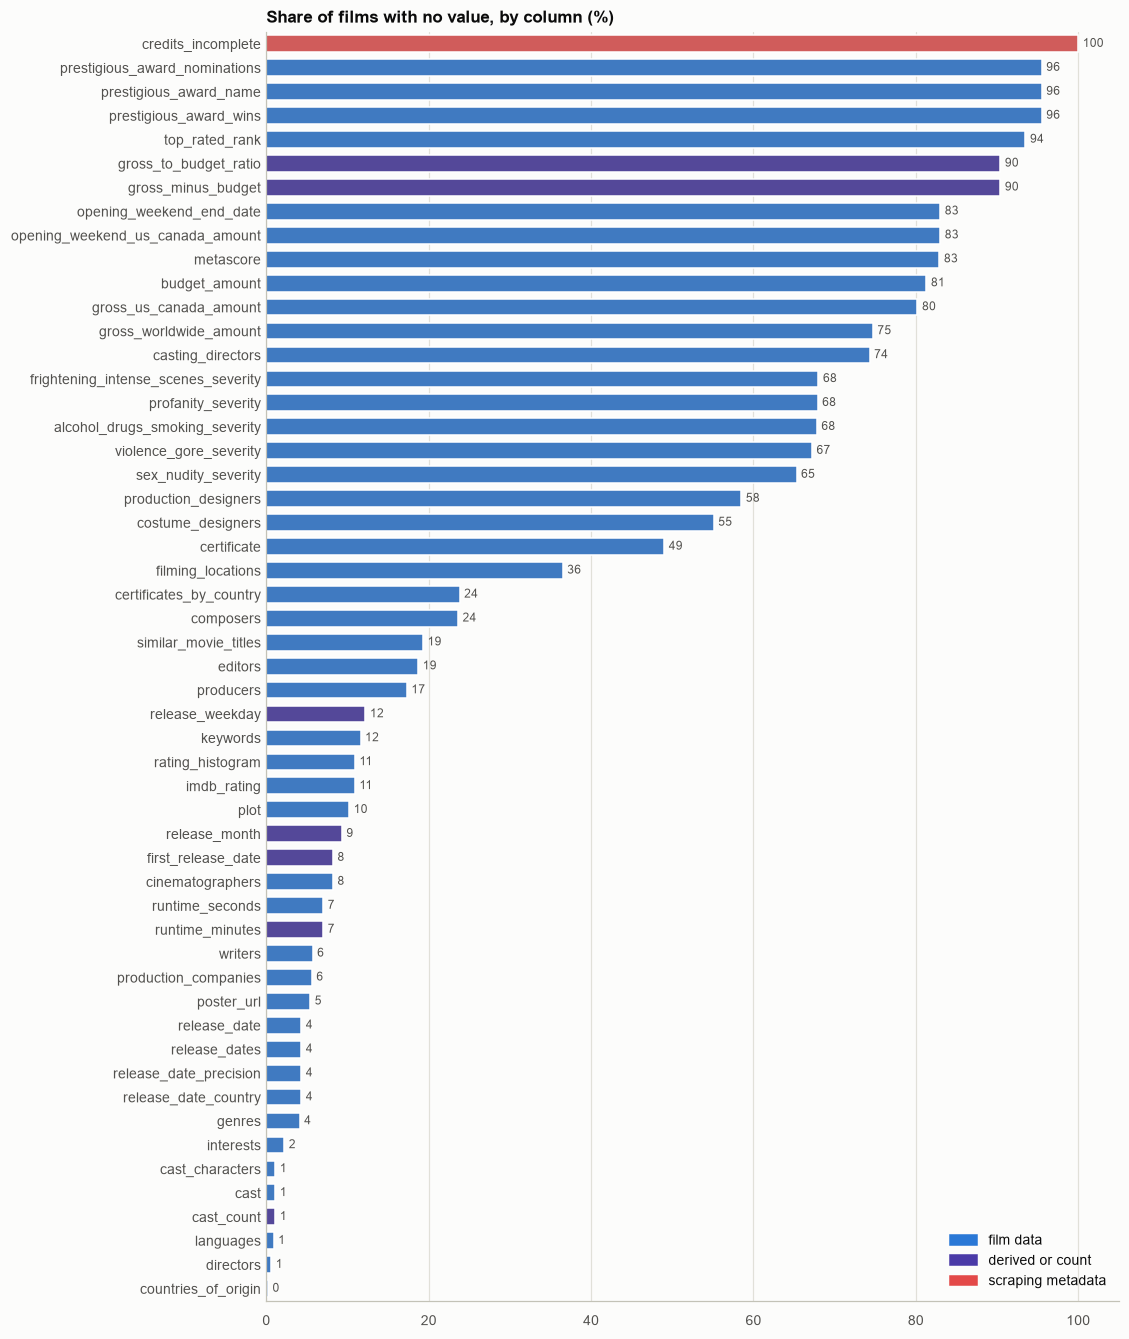

In [7]:
missing = inventory.loc[~inventory.index.str.endswith(("_ids", "_currency")) & (inventory["missing %"] > 0)]
missing = missing.sort_values("missing %", ascending=False)
barh(missing["missing %"].astype(float), "Share of films with no value, by column (%)",
     colors=[ROLES[r] for r in missing["role"]], legend=ROLES, fmt="{:.0f}")

### 2.2 Columns that can be computed from others

Each line compares a column with what it should equal and gives the share of films where both agree. At 100% the column adds nothing.

In [8]:
def n_items(column, skip=()):
    """Number of elements in a list column; a missing list counts as empty."""
    return movies[column].map(lambda items: sum(item not in skip for item in items), na_action="ignore").astype(float).fillna(0)


def agreement(column, expected):
    actual = movies[column]
    both = actual.notna() & expected.notna()
    if actual.dtype.kind in "iuf":
        equal = np.isclose(actual[both].astype(float), expected[both].astype(float), rtol=1e-3, atol=1e-3)
    else:
        equal = actual[both] == expected[both]
    return round(float(np.mean(equal)) * 100, 2)


gross, budget = movies["gross_worldwide_amount"], movies["budget_amount"]
same_currency = movies["gross_worldwide_currency"] == movies["budget_currency"]
RELATIONS = {
    "listing_title": ("title", movies["title"]),
    "original_title": ("title", movies["title"]),
    "search_year": ("release_year", movies["release_year"]),
    "release_decade": ("release_year // 10 * 10", movies["release_year"] // 10 * 10),
    "runtime_minutes": ("runtime_seconds / 60", movies["runtime_seconds"] / 60),
    "cast_count": ("number of cast entries", n_items("cast").where(movies["cast"].notna())),
    "cast_total": ("number of cast entries", n_items("cast")),
    "genre_count": ("number of genres", n_items("genres")),
    "country_count": ("number of countries", n_items("countries_of_origin")),
    "language_count": ("number of languages without 'None'", n_items("languages", skip=("None",))),
    "release_dates_total": ("number of release dates", n_items("release_dates")),
    "gross_minus_budget": ("worldwide gross - budget", (gross - budget).where(same_currency)),
    "gross_to_budget_ratio": ("(worldwide gross - budget) / budget", ((gross - budget) / budget).where(same_currency)),
    "similar_movies_status": ("'found' when there are similar movies", movies["similar_movie_ids"].notna().map({True: "found", False: "empty"})),
    "keywords_total": ("number of keywords kept", n_items("keywords")),
    "filming_locations_total": ("number of filming locations kept", n_items("filming_locations")),
}
redundancy = pd.DataFrame([{"column": column, "compared with": name, "agreement %": agreement(column, expected)}
                           for column, (name, expected) in RELATIONS.items()])
redundancy["verdict"] = np.where(redundancy["agreement %"] >= 99.9, "redundant", "keep")
display(redundancy)

,column,compared with,agreement %,verdict
0,listing_title,title,100.00,redundant
1,original_title,title,78.81,keep
2,search_year,release_year,99.97,redundant
3,release_decade,release_year // 10 * 10,100.00,redundant
4,runtime_minutes,runtime_seconds / 60,100.00,redundant
5,cast_count,number of cast entries,100.00,redundant
6,cast_total,number of cast entries,100.00,redundant
7,genre_count,number of genres,100.00,redundant
8,country_count,number of countries,100.00,redundant
9,language_count,number of languages without 'None',100.00,redundant


Three columns need a word more:

- **`original_title`** differs from `title` for a fifth of the films, so it stays.
- **`keywords_total` and `filming_locations_total`** stay too: the lists are capped (5 keywords, 1 filming location), so these totals are the real counts.
- **`akas_total`** goes even though it is not in the table: the AKA lists are complete, so it only counts their rows, with or without the original-title row depending on the film.

Other derived columns follow later, in their own sections: `first_release_date` with the release dates (4.4) and `release_year` once every film has a release date.

### 2.3 Films outside the dataset

The dataset covers released feature films. Two kinds of rows fall outside it: films that were never released, and films shorter than 40 minutes, the usual threshold for a feature (AMPAS, BFI).

,check,films,examples
0,"never released (abandoned, in production, ...)",82,"[L'école des femmes (tt0278164), Kaleidoscope (tt6914094), L'uomo ..."
1,shorter than 40 minutes,12,"[Sol, sommer og studiner (tt0012710), Baptême du Belgenland par S...."


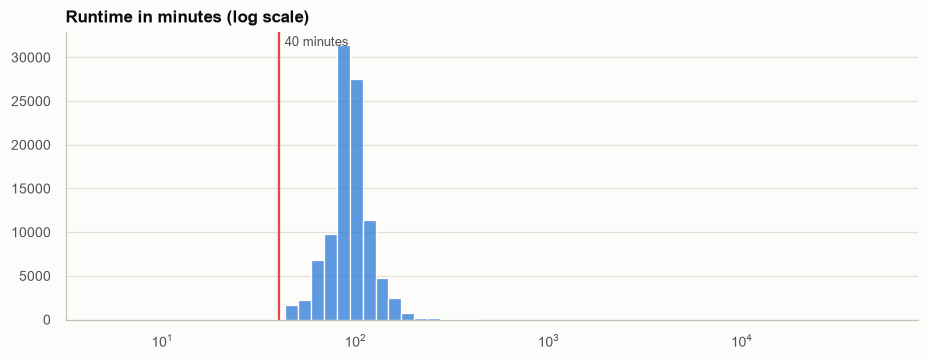

In [9]:
runtime = movies["runtime_minutes"]
OUT_OF_SCOPE = {
    "never released (abandoned, in production, ...)": movies["production_status"].fillna("unknown") != "released",
    "shorter than 40 minutes": runtime < 40,
}
display(check_table(OUT_OF_SCOPE))

fig, ax = plt.subplots(figsize=(10, 3.4))
sns.histplot(runtime.dropna().astype(float), log_scale=True, bins=60, color=BLUE, ax=ax)
ax.axvline(40, color=RED, linewidth=1.5)
ax.annotate("40 minutes", (40, 0.95), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points",
            color=INK_2, fontsize=8.5)
ax.set(xlabel="", ylabel="")
ax.grid(axis="x", visible=False)
ax.set_title("Runtime in minutes (log scale)")
plt.show()

Very long runtimes are genuine: serials, multi-part films and experimental works such as *Logistics* (2012), which lasts 35 days. They stay.

## 3. Reductions

### 3.1 Remove the films outside the dataset

In [10]:
outside = pd.concat(OUT_OF_SCOPE.values(), axis=1).fillna(False).any(axis=1)
movies = movies.loc[~outside].reset_index(drop=True)
LOG["films removed (never released or under 40 minutes)"] = int(outside.sum())
print(f"{int(outside.sum())} films removed; {len(movies):,} remain.")

94 films removed; 106,905 remain.


### 3.2 Remove the columns that carry no information

- **Scraping metadata** describes the scraping run, not the films.
- **Single-value columns** never vary. `production_status` joins them now that only released films remain.
- **Recomputable columns** are exact functions of other columns (section 2.2).

In [11]:
DROPPED = {
    "scraping metadata": SCRAPING,
    "single value": ["title_type", "is_adult", "opening_weekend_us_canada_currency", "gross_comparison_currency",
                     "production_status"],
    "recomputable": ["runtime_seconds", "release_decade", "release_month", "release_weekday", "cast_count", "cast_total",
                     "genre_count", "country_count", "language_count", "release_dates_total", "akas_total",
                     "gross_minus_budget", "gross_to_budget_ratio"],
}
assert all(movies[column].dropna().nunique() <= 1 for column in DROPPED["single value"])
movies = movies.drop(columns=[column for columns in DROPPED.values() for column in columns])
LOG["columns removed as no-information"] = sum(len(columns) for columns in DROPPED.values())
display(pd.DataFrame([{"reason": reason, "columns": len(columns), "names": ", ".join(columns)}
                      for reason, columns in DROPPED.items()]))
print(f"{n_columns} columns -> {movies.shape[1]}")

,reason,columns,names
0,scraping metadata,7,"search_year, listing_rank, listing_title, scraped_at, similar_movi..."
1,single value,5,"title_type, is_adult, opening_weekend_us_canada_currency, gross_co..."
2,recomputable,13,"runtime_seconds, release_decade, release_month, release_weekday, c..."


98 columns -> 73


## 4. Field groups, one by one

### 4.1 Text

Every string is checked, in every column and inside every list and record. A pre-filter keeps the strings that contain a non-ASCII character, edge or double spaces, or an `&`; the issue checks run on those.

| Issue | Example | What happens |
| --- | --- | --- |
| Edge or repeated whitespace, non-standard spaces, line breaks | `'Silvino Salas 'Sal' '` | Collapsed to single spaces and trimmed |
| Invisible format characters (zero-width space, soft hyphen, BOM, direction marks) | | Removed |
| Zero-width joiners | ZWNJ in Persian titles | Kept inside Arabic-script and Indic words, where they are part of the spelling; removed elsewhere |
| Control characters | U+0082 | Removed, after the encoding repair has used them |
| HTML entities | `&#1052;&#1086;...` | Decoded |
| Broken encodings (mojibake) | `estÃ¡` instead of `está` | Repaired |
| Not in NFC | | Composed into NFC, which loses nothing |
| Changes under NFKC | `8½`, `Dª`, full-width brackets | Left alone: these characters are used on purpose |

The patterns are built from code points with `char_class`, so the notebook's own source contains no invisible characters.

24,763,350 strings checked.


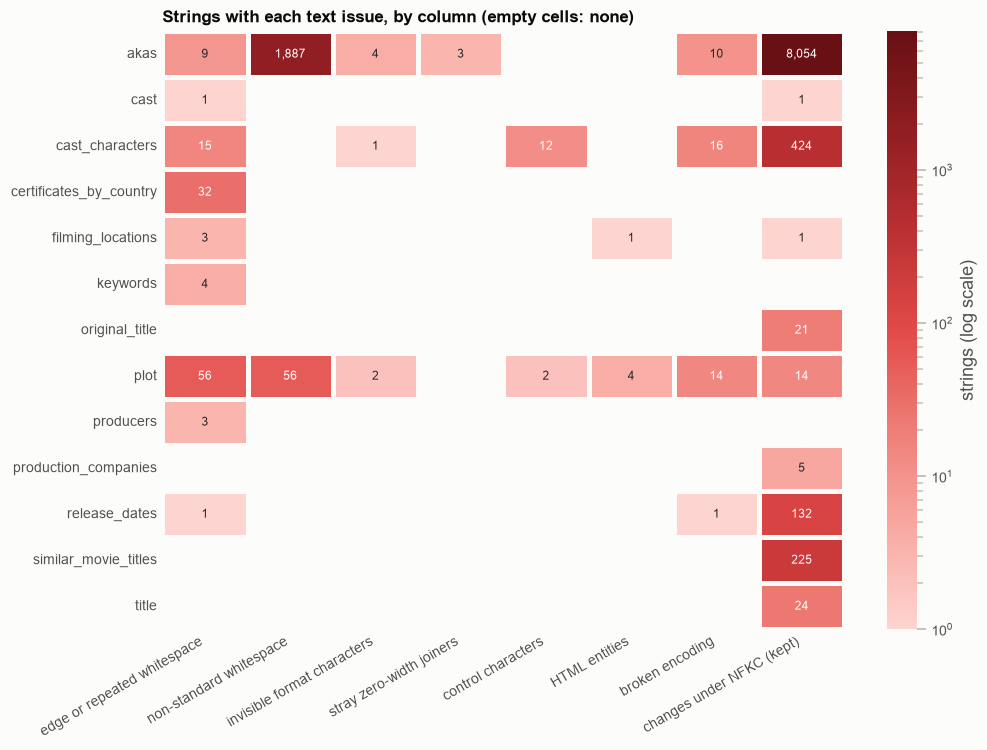

In [12]:
def char_class(*points):
    """A regex character class from code points and (first, last) ranges."""
    parts = []
    for point in points:
        first, last = point if isinstance(point, tuple) else (point, point)
        parts.append(re.escape(chr(first)) + ("-" + re.escape(chr(last)) if last != first else ""))
    return "[" + "".join(parts) + "]"


ODD_SPACES = char_class(0x00A0, 0x1680, (0x2000, 0x200A), 0x202F, 0x205F, 0x3000, (0x09, 0x0D))
INVISIBLE_CHARS = char_class(0x00AD, 0x180E, 0x200B, 0x200E, 0x200F, 0x2028, 0x2029, (0x202A, 0x202E),
                             (0x2060, 0x2064), (0x2066, 0x2069), 0xFEFF)
CONTROL_CHARS = char_class((0x00, 0x08), 0x0B, 0x0C, (0x0E, 0x1F), (0x7F, 0x9F))
JOINERS = char_class(0x200C, 0x200D)
JOINING_SCRIPTS = char_class((0x0600, 0x06FF), (0x0750, 0x077F), (0x08A0, 0x08FF), (0xFB50, 0xFDFF),
                             (0xFE70, 0xFEFE), (0x0900, 0x0DFF))
STRAY_JOINER = f"(?<!{JOINING_SCRIPTS}){JOINERS}|{JOINERS}(?!{JOINING_SCRIPTS})"
MOJIBAKE = "[ÃÂ][\x80-\xbf]|â€|Å[\x80-\xbfŒœŠšŸŽž‘’‚“”„†‡•…‰‹›€™]|[\x80-\x9f]"
ENTITY = r"&(?:[a-zA-Z]{2,8}|#\d{2,5}|#x[0-9a-fA-F]{2,4});"
SUSPECT = r"[^\x20-\x7e]|^\s|\s$|\s\s|&"


def flatten(values):
    """Every string inside the values, however deeply nested in lists and records."""
    texts, pending = [], list(values)
    while pending:
        texts += [value for value in pending if isinstance(value, str)]
        nested = [value for value in pending if isinstance(value, (list, dict))]
        pending = [item for value in nested for item in (value.values() if isinstance(value, dict) else value)]
    return texts


def text_audit(frame):
    """Number of strings with each issue, by column, and the number of strings checked."""
    needs_work = re.compile(SUSPECT).search
    parts, total = [], 0
    for column in frame.columns:
        texts = flatten(frame[column].dropna())
        total += len(texts)
        parts.append(pd.DataFrame({"column": column, "text": [text for text in texts if needs_work(text)]}))
    suspect = pd.concat(parts, ignore_index=True)
    s = suspect["text"]
    issues = pd.DataFrame({
        "edge or repeated whitespace": s.str.contains(r"^\s|\s$|\s\s"),
        "non-standard whitespace": s.str.contains(ODD_SPACES),
        "invisible format characters": s.str.contains(INVISIBLE_CHARS),
        "stray zero-width joiners": s.str.contains(STRAY_JOINER),
        "control characters": s.str.contains(CONTROL_CHARS),
        "HTML entities": s.str.contains(ENTITY),
        "broken encoding": s.str.contains(MOJIBAKE),
        "not NFC": ~s.map(lambda value: unicodedata.is_normalized("NFC", value)),
        "empty": s.str.strip().eq(""),
        "changes under NFKC (kept)": ~s.map(lambda value: unicodedata.is_normalized("NFKC", value)),
    })
    return issues.groupby(suspect["column"]).sum(), total


audit_before, n_strings = text_audit(movies)
shown = audit_before.loc[audit_before.sum(axis=1) > 0, audit_before.sum() > 0]
print(f"{n_strings:,} strings checked.")
heatmap(shown, "Strings with each text issue, by column (empty cells: none)", REDS, "strings (log scale)",
        mask=shown == 0, norm=LogNorm(vmin=1, vmax=shown.to_numpy().max()), annot=True, fmt=",", annot_kws={"fontsize": 8})

Every string then goes through the same steps:

1. **HTML entities** are decoded.
2. **A few strings that no tool can repair are fixed by hand** (`MANUAL_FIXES`), for example `Malgo\x9cka`, whose byte is a Polish ś.
3. **ftfy repairs the remaining broken encodings,** but only in strings that match the broken-encoding pattern. Run on everything, it damages correct text: it turns the real title *Â bakudan* into " bakudan" and garbles some Cyrillic titles.
4. **NFC normalization.**
5. **Invisible and control characters are removed,** keeping the joiners that belong to the spelling.
6. **Whitespace is collapsed and trimmed.**

Entries that end up empty are dropped. Lists of labels also lose repeated entries, but lists of people keep every position: a repeated name there is a different person with the same name.

In [13]:
MANUAL_FIXES = {  # broken beyond automatic repair; the right text is clear from context
    "MelquÃ\x8dÂades": "Melquíades",
    "Malgo\x9cka": "Malgośka",        # Windows-1250 byte for ś, which ftfy would read as œ
    "FaÃfffÃf'Ã'Â¯d": "Faïd",
    'Ã¢ÂEURÂ"': "—",                  # an em dash encoded three times
    "â€TM": "’",                      # an apostrophe whose ™ byte was written as "TM"
}
FTFY = ftfy.TextFixerConfig(unescape_html=False, fix_character_width=False, uncurl_quotes=False,
                            fix_latin_ligatures=False, fix_line_breaks=False, normalization=None)
NEEDS_WORK, IS_ENTITY, IS_MOJIBAKE = re.compile(SUSPECT), re.compile(ENTITY), re.compile(MOJIBAKE)
REMOVE = re.compile(f"{INVISIBLE_CHARS}|{CONTROL_CHARS}|{STRAY_JOINER}")
CHANGES = Counter()


def step(name, before, after):
    if after != before:
        CHANGES[name] += 1
    return after


def clean_text(text):
    """Repair and normalize one string; None when nothing is left."""
    if not NEEDS_WORK.search(text):
        return text
    if IS_ENTITY.search(text):
        text = step("HTML entities decoded", text, html.unescape(text))
    for broken, fixed in MANUAL_FIXES.items():
        if broken in text:
            text = step("repaired by hand", text, text.replace(broken, fixed))
    if IS_MOJIBAKE.search(text):
        text = step("broken encoding repaired (ftfy)", text, ftfy.fix_text(text, config=FTFY))
    text = step("normalized to NFC", text, unicodedata.normalize("NFC", text))
    text = step("invisible or control characters removed", text, REMOVE.sub("", text))
    text = step("whitespace normalized", text, " ".join(text.split()))
    return text or None


PEOPLE = [*CREDIT_GROUPS, *[f"{group}_ids" for group in CREDIT_GROUPS], "similar_movie_ids", "similar_movie_titles"]
REQUIRED_FIELD = {"akas": "title", "release_dates": "date", "certificates_by_country": "rating"}


def clean_column(column):
    """Clean every string of a column, keeping the shape its kind of data needs."""
    values = movies[column]
    if column in REQUIRED_FIELD:
        required = REQUIRED_FIELD[column]

        def clean_records(records):
            kept = []
            for record in records:
                record = {key: clean_text(value) if isinstance(value, str) else value for key, value in record.items()}
                if record.get(required) and record not in kept:
                    kept.append(record)
            return kept or None
        return values.map(clean_records, na_action="ignore")
    if column == "cast_characters":
        return values.map(lambda people: [[c for c in map(clean_text, characters) if c] for characters in people],
                          na_action="ignore")
    if column in PEOPLE:
        return values.map(lambda items: [clean_text(item) for item in items], na_action="ignore")
    if column in JSON_COLUMNS:
        return values.map(lambda items: list(dict.fromkeys(i for i in map(clean_text, items) if i)) or None, na_action="ignore")
    return values.map(clean_text, na_action="ignore")


TEXT_COLUMNS = [column for column in movies.columns if column != "rating_histogram"
                and not pd.api.types.is_numeric_dtype(movies[column]) and not pd.api.types.is_datetime64_any_dtype(movies[column])]
for column in TEXT_COLUMNS:
    movies[column] = clean_column(column)
LOG["strings repaired or normalized"] = sum(CHANGES.values())
display(pd.Series(CHANGES, name="strings changed").rename_axis("step").to_frame())

,strings changed
step,
whitespace normalized,2006
broken encoding repaired (ftfy),38
HTML entities decoded,5
repaired by hand,6
normalized to NFC,2
invisible or control characters removed,8


Section 6.1 runs the same audit on the final table and compares it with the one above.

### 4.2 Label lists

The label lists are `genres`, `interests`, `keywords`, `countries_of_origin`, `languages`, `production_companies` and `filming_locations`, plus the notes and ratings inside the records. Five things change:

1. **Case variants.** The same value spelled with different case (`Re-release` and `re-release`, `PoliceMan` and `Policeman`) becomes its most frequent spelling. This applies to labels and character names; titles, people's names and plots keep their case.
2. **`interests`.** It repeats two other columns: genre names that are already in `genres`, and language names that are already in `languages` (every film with the interest "Spanish" lists Spanish as a language). Both go, leaving sub-genres, themes and franchises such as *Dark Comedy*, *Slapstick* or *Stargate*.
3. **`languages`.** IMDb's placeholder `None`, used for films without spoken language, becomes `silent_movie`.
4. **`filming_locations`.** It never holds more than one place, so it becomes the text column `filming_location`. `filming_locations_total` keeps the real count.
5. **`akas`.** Its "original title" row repeats `original_title`, so it goes.

`keywords` is clean already (all lowercase) and stays as it is: IMDb shows the first 5 keywords of a film, and `keywords_total` gives how many it has.

In [14]:
def most_common_spelling(values):
    """Map each spelling to the most frequent spelling of its case-insensitive group (only spellings that change)."""
    groups = {}
    for value, count in Counter(values).items():
        groups.setdefault(value.casefold(), []).append((-count, value))
    return {value: min(group)[1] for group in groups.values() if len(group) > 1 for _, value in group if value != min(group)[1]}


LABEL_LISTS = ["genres", "interests", "keywords", "countries_of_origin", "languages", "production_companies", "filming_locations"]
unified = {}
for column in LABEL_LISTS:
    mapping = unified[column] = most_common_spelling(movies[column].explode().dropna())
    movies[column] = movies[column].map(lambda values: list(dict.fromkeys(mapping.get(v, v) for v in values)), na_action="ignore")
mapping = unified["cast_characters"] = most_common_spelling(movies["cast_characters"].explode().dropna().explode().dropna())
movies["cast_characters"] = movies["cast_characters"].map(
    lambda people: [[mapping.get(name, name) for name in characters] for characters in people], na_action="ignore")
for column, field in [("akas", "note"), ("release_dates", "note"), ("certificates_by_country", "rating"),
                      ("certificates_by_country", "notes")]:
    mapping = unified[f"{column}.{field}"] = most_common_spelling(movies[column].explode().dropna().map(lambda r: r[field]).dropna())
    movies[column] = movies[column].map(
        lambda records: [{**record, field: mapping.get(record[field], record[field])} for record in records], na_action="ignore")
LOG["spellings unified"] = sum(len(mapping) for mapping in unified.values())

genre_names = set(movies["genres"].explode().dropna())
language_names = set(movies["languages"].explode().dropna())
interests_before = movies["interests"].explode().notna().sum()
movies["interests"] = movies["interests"].map(
    lambda values: [v for v in values if v not in genre_names and v not in language_names] or None, na_action="ignore")
movies["languages"] = movies["languages"].map(lambda values: ["silent_movie" if v == "None" else v for v in values],
                                              na_action="ignore")
assert movies["filming_locations"].str.len().max() == 1
movies["filming_location"] = movies.pop("filming_locations").str[0]
movies["akas"] = movies["akas"].map(lambda akas: [aka for aka in akas if aka["note"] != "original title"] or None,
                                    na_action="ignore")
LOG["genre and language names removed from interests"] = int(interests_before - movies["interests"].explode().notna().sum())
LOG["films with silent_movie"] = int(movies["languages"].map(lambda values: "silent_movie" in values, na_action="ignore").sum())

display(pd.DataFrame([{"field": field, "spellings unified": len(mapping),
                       "for example": "; ".join(f"{old} -> {new}" for old, new in list(mapping.items())[:2])}
                      for field, mapping in unified.items() if mapping]))
print(f"interests: {interests_before:,} -> {movies['interests'].explode().notna().sum():,} entries; "
      f"{movies['interests'].notna().mean():.0%} of films keep at least one.")
print(f"silent_movie: {LOG['films with silent_movie']:,} films.")

,field,spellings unified,for example
0,production_companies,68,Star-film -> Star-Film; Kinostudiya Imeni M. Gorkogo -> Kinostudiy...
1,filming_locations,11,"los angeles, California, USA -> Los Angeles, California, USA; Stud..."
2,cast_characters,15225,A murderer -> A Murderer; The landlady -> The Landlady
3,release_dates.note,469,"New York CIty, New York -> New York City, New York; Re-release -> ..."
4,certificates_by_country.rating,5,a -> A; Not rated -> Not Rated
5,certificates_by_country.notes,111,streaming rating -> Streaming rating; Streaming Rating -> Streamin...


interests: 326,470 -> 57,342 entries; 27% of films keep at least one.
silent_movie: 8,907 films.


### 4.3 The certificate (age rating)

`certificate` is the rating IMDb shows on a film's page. It mixes several US rating systems:

- **Current MPA ratings:** G, PG, PG-13, R, NC-17.
- **Older MPA ratings:** GP, M, M/PG and X.
- **Production Code clearances (before 1968):** Approved and Passed.
- **US TV ratings:** the TV-* labels.
- **Streaming labels:** 13+, 16+ and 18+.
- **One-offs:** video-game ratings and isolated labels.
- **No rating:** Not Rated and Unrated.

About half the films have no certificate.

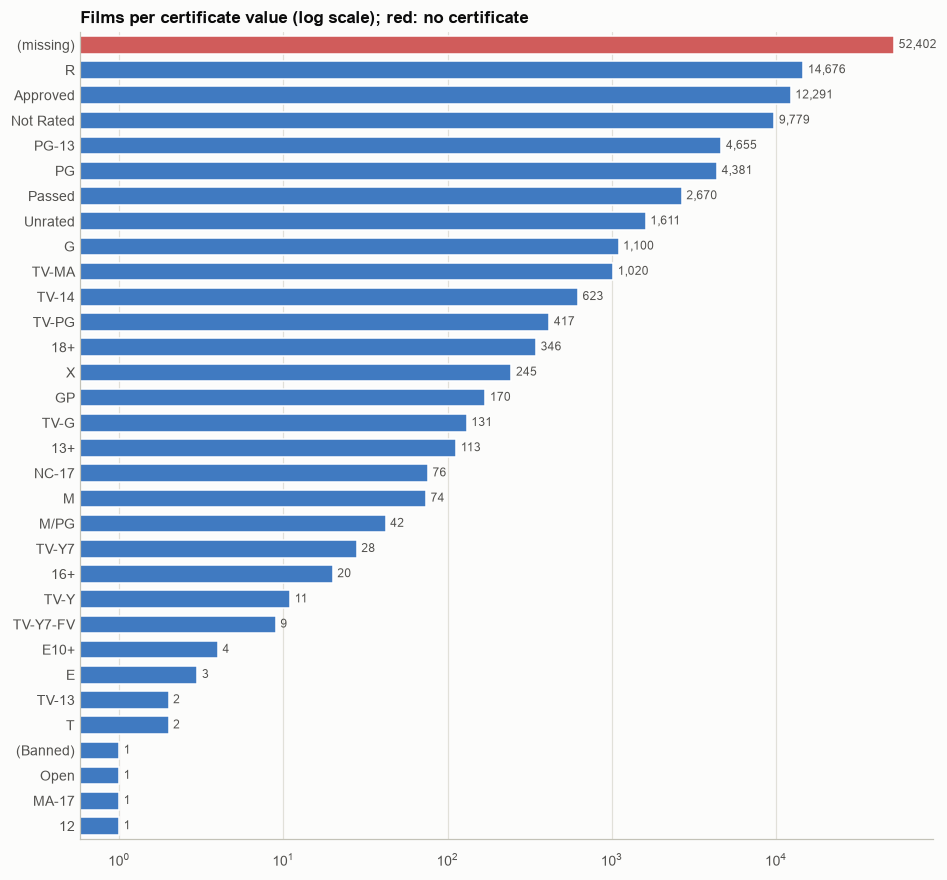

In [15]:
counts = movies["certificate"].fillna("(missing)").value_counts()
barh(counts, "Films per certificate value (log scale); red: no certificate",
     colors=[RED if label == "(missing)" else BLUE for label in counts.index], log=True)

When the title page has no certificate, the first **theatrical** US rating in `certificates_by_country` fills it. TV, DVD, video, cable and streaming ratings are skipped. Certificates still missing after that stay missing: an unknown rating is not the same as an explicit "Not Rated".

Each label then gets an age group and a minimum age. The grouping follows the original cleaning notebook, with three changes:

- **Approved and Passed** get their own group, because they are clearances rather than age ratings.
- **Unrated films** get no minimum age.
- **New labels** that notebook did not have are placed in a group.

85 certificates filled from US theatrical ratings.


,minimum age,labels,films
age_group,,,
general,0.0,"G, TV-G, TV-Y",1245
parental_guidance,7.0,"PG, GP, M, M/PG, TV-PG, TV-Y7, TV-Y7-FV, E10+",5131
teen,13.0,"PG-13, TV-14, TV-13, 13+, T, 12",5398
mature,17.0,"R, TV-MA, MA-17, 16+",15748
adults_only,18.0,"NC-17, X, 18+",673
approved,NaN,"Approved, Passed",14989
unrated,NaN,"Not Rated, Unrated, Open, (Banned), E",11404
(missing),NaN,,52317


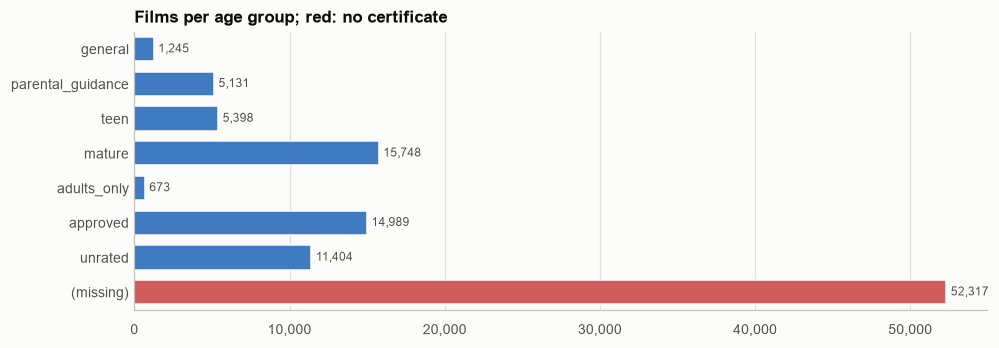

In [16]:
NON_THEATRICAL = re.compile("tv|dvd|video|cable|streaming", re.IGNORECASE)


def us_theatrical(certificates):
    """The first US rating that is not a TV, DVD, video, cable or streaming rating."""
    for entry in certificates:
        if (entry["country"] == "United States" and not entry["rating"].startswith("TV-")
                and not NON_THEATRICAL.search(entry.get("notes") or "")):
            return entry["rating"]
    return None


from_us = movies["certificates_by_country"].map(us_theatrical, na_action="ignore")
to_fill = movies["certificate"].isna() & from_us.notna()
movies.loc[to_fill, "certificate"] = from_us[to_fill]
LOG["certificates filled from US theatrical ratings"] = int(to_fill.sum())

AGE_GROUPS = {  # group: (minimum age, labels)
    "general": (0, ["G", "TV-G", "TV-Y"]),
    "parental_guidance": (7, ["PG", "GP", "M", "M/PG", "TV-PG", "TV-Y7", "TV-Y7-FV", "E10+"]),
    "teen": (13, ["PG-13", "TV-14", "TV-13", "13+", "T", "12"]),
    "mature": (17, ["R", "TV-MA", "MA-17", "16+"]),
    "adults_only": (18, ["NC-17", "X", "18+"]),
    "approved": (None, ["Approved", "Passed"]),
    "unrated": (None, ["Not Rated", "Unrated", "Open", "(Banned)", "E"]),
}
GROUP_OF = {label: group for group, (_, labels) in AGE_GROUPS.items() for label in labels}
assert set(movies["certificate"].dropna()) <= set(GROUP_OF), set(movies["certificate"].dropna()) - set(GROUP_OF)
movies["age_group"] = movies["certificate"].map(GROUP_OF)
movies["min_age"] = movies["age_group"].map({group: age for group, (age, _) in AGE_GROUPS.items()}).astype("Int64")

films = movies["age_group"].fillna("(missing)").value_counts().reindex([*AGE_GROUPS, "(missing)"], fill_value=0)
print(f"{int(to_fill.sum())} certificates filled from US theatrical ratings.")
display(pd.DataFrame({"minimum age": [AGE_GROUPS[g][0] if g in AGE_GROUPS else None for g in films.index],
                      "labels": [", ".join(AGE_GROUPS[g][1]) if g in AGE_GROUPS else "" for g in films.index],
                      "films": films.to_numpy()}, index=films.index))
barh(films, "Films per age group; red: no certificate", colors=[RED if g == "(missing)" else BLUE for g in films.index])

### 4.4 Release dates

`release_date` used to hold the release IMDb displays on the title page, which is a regional one. It now holds the **earliest** entry of `release_dates`, at its own precision: `1955`, `1955-05` or `1955-05-17`. `release_date_precision` says which, and `release_country` says where.

Two rules decide what counts as earliest:

- **A more precise date inside the same period wins.** If a partial date's year or month contains a full date, the full date is used: `1956` and `1956-03-01` give `1956-03-01`.
- **A partial date in an earlier period wins,** because that release came first.

For films without any release date, `release_date` takes `release_year`, at year precision. That makes `release_year` and `first_release_date` redundant, so both go.

In [17]:
PRECISION = {10: "day", 7: "month", 4: "year"}


def period_start(entry):
    return entry["date"] + "-01-01"[: 10 - len(entry["date"])]


def earliest_release(entries):
    """The earliest release; a partial date gives way to a more precise date inside its own year or month."""
    best = min(entries, key=period_start)
    inside = [e for e in entries if len(e["date"]) > len(best["date"]) and e["date"].startswith(best["date"])]
    while inside:
        best = min(inside, key=period_start)
        inside = [e for e in entries if len(e["date"]) > len(best["date"]) and e["date"].startswith(best["date"])]
    return best


earliest = movies["release_dates"].map(earliest_release, na_action="ignore")
has_list = earliest.notna()
movies.loc[has_list, "release_date"] = earliest[has_list].map(lambda entry: entry["date"])
movies.loc[has_list, "release_date_precision"] = earliest[has_list].map(lambda entry: PRECISION[len(entry["date"])])
movies.loc[has_list, "release_date_country"] = earliest[has_list].map(lambda entry: entry["country"])
year_only = movies["release_date"].isna() & movies["release_year"].notna()
movies.loc[year_only, "release_date"] = movies.loc[year_only, "release_year"].astype(str)
movies.loc[year_only, "release_date_precision"] = "year"
differs = has_list & (pd.to_numeric(movies["release_date"].str[:4]) != movies["release_year"])
movies = movies.rename(columns={"release_date_country": "release_country"}).drop(columns=["release_year", "first_release_date"])
LOG["release dates set to the earliest release"] = int(has_list.sum())
LOG["release dates taken from release_year"] = int(year_only.sum())

print(f"Earliest release for {has_list.sum():,} films; release_year used for {year_only.sum():,} films without any date; "
      f"for {differs.sum():,} films the earliest release falls in another year than IMDb's release_year.")
display(movies["release_date_precision"].value_counts(dropna=False).rename("films").to_frame())

Earliest release for 102,335 films; release_year used for 4,569 films without any date; for 593 films the earliest release falls in another year than IMDb's release_year.


,films
release_date_precision,
day,92347
year,8379
month,6179


### 4.5 Money

Amounts are in their own currency, given as an ISO 4217 code such as USD, never as a symbol. They are not converted, because converting would need historical exchange rates and inflation data. Two kinds of values are clearly wrong and become missing, together with their currency:

- **Amounts of exactly 0,** in any currency.
- **Budgets under 1,000 USD.**

Small budgets in other currencies stay: judging them would need a conversion. The opening-weekend currency was always USD and went in section 3.2, so its amount is renamed `opening_weekend_us_canada_usd` to keep the unit visible.

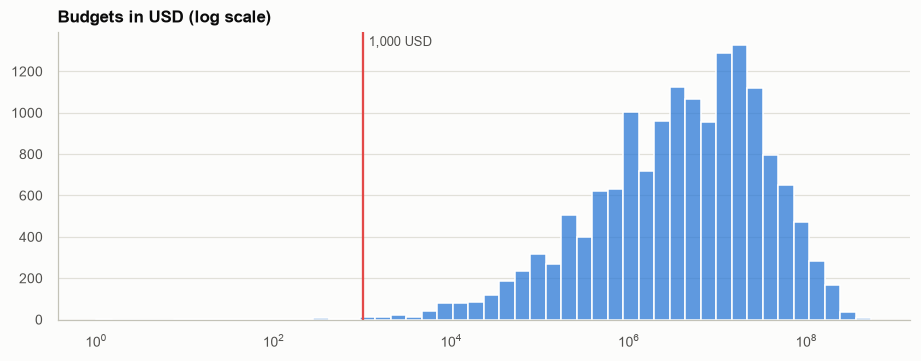

,check,films,examples
0,invalid budget_amount,73,"[Dr. Mabuse, der spieler: Teil II: Inferno (tt43521150), A Pirate ..."
1,invalid gross_us_canada_amount,0,[]
2,invalid gross_worldwide_amount,1,[The Little Sister (tt0087633)]
3,invalid opening_weekend_us_canada_amount,1,[American Wrestler: The Wizard (tt4303202)]


In [18]:
usd_budget = movies.loc[movies["budget_currency"] == "USD", "budget_amount"]
fig, ax = plt.subplots(figsize=(10, 3.4))
sns.histplot(usd_budget[usd_budget > 0].astype(float), log_scale=True, bins=50, color=BLUE, ax=ax)
ax.axvline(1_000, color=RED, linewidth=1.5)
ax.annotate("1,000 USD", (1_000, 0.95), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points",
            color=INK_2, fontsize=8.5)
ax.set(xlabel="", ylabel="")
ax.grid(axis="x", visible=False)
ax.set_title("Budgets in USD (log scale)")
plt.show()

INVALID = {
    "budget_amount": movies["budget_amount"].eq(0) | (movies["budget_currency"].eq("USD") & movies["budget_amount"].lt(1_000)),
    "gross_us_canada_amount": movies["gross_us_canada_amount"].eq(0),
    "gross_worldwide_amount": movies["gross_worldwide_amount"].eq(0),
    "opening_weekend_us_canada_amount": movies["opening_weekend_us_canada_amount"].eq(0),
}
display(check_table({f"invalid {amount}": flags for amount, flags in INVALID.items()}))
for amount, flags in INVALID.items():
    currency = amount.replace("_amount", "_currency")
    movies.loc[flags.fillna(False).to_numpy(dtype=bool), [amount, currency] if currency in movies else [amount]] = None
movies = movies.rename(columns={"opening_weekend_us_canada_amount": "opening_weekend_us_canada_usd"})
LOG["invalid amounts removed"] = int(sum(flags.fillna(False).sum() for flags in INVALID.values()))

### 4.6 Ratings and awards

- **Ratings and votes agree.** A film with no votes has `imdb_votes` = 0 and no rating, so nothing needs filling.
- **Award counts.** They already use 0 for "none". The exception is the prestigious award (Oscar, BAFTA, ...): its wins and nominations are missing when IMDb singles out no such award. They become 0, like the other counts.

In [19]:
print(pd.crosstab(movies["imdb_votes"].eq(0).rename("no votes"), movies["imdb_rating"].isna().rename("no rating")))
no_award = movies["prestigious_award_name"].isna()
assert movies.loc[no_award, ["prestigious_award_wins", "prestigious_award_nominations"]].isna().all().all()
movies.loc[no_award, ["prestigious_award_wins", "prestigious_award_nominations"]] = 0
LOG["prestigious-award counts set to 0"] = int(no_award.sum())

no rating  False  True 
no votes               
False      95369      0
True           0  11535


### 4.7 Credits and similar movies

Each credit group used three parallel lists: names, IDs and, for the cast, characters. They become one list of records: `{id, name}`, or `{id, name, characters}` for the cast. The similar movies become `{id, title}` records.

Records keep together the values that belong together, so no list can drift out of step with another. In the CSV each record becomes a plain array, such as `["nm0001104", "Frank Darabont"]`, which keeps the file small (section 5).

In [20]:
def records(*parallel, keys):
    """Zip one film's parallel lists into records; None when the film has none."""
    if not isinstance(parallel[0], list):
        return None
    assert len({len(values) for values in parallel}) == 1, "parallel lists of different lengths"
    return [dict(zip(keys, values)) for values in zip(*parallel)]


for group in CREDIT_GROUPS:
    ids, names = movies.pop(f"{group}_ids"), movies[group]
    if group == "cast":
        movies[group] = [records(i, n, c, keys=("id", "name", "characters"))
                         for i, n, c in zip(ids, names, movies.pop("cast_characters"))]
    else:
        movies[group] = [records(i, n, keys=("id", "name")) for i, n in zip(ids, names)]
movies["similar_movies"] = [records(i, t, keys=("id", "title"))
                            for i, t in zip(movies.pop("similar_movie_ids"), movies.pop("similar_movie_titles"))]
example = movies["imdb_votes"].idxmax()
print(movies.at[example, "title"], "->", movies.at[example, "directors"], movies.at[example, "cast"][:2])

The Shawshank Redemption -> [{'id': 'nm0001104', 'name': 'Frank Darabont'}] [{'id': 'nm0000209', 'name': 'Tim Robbins', 'characters': ['Andy Dufresne']}, {'id': 'nm0000151', 'name': 'Morgan Freeman', 'characters': ["Ellis Boyd 'Red' Redding"]}]


## 5. Types and size

### 5.1 Where the size comes from

In a CSV, every value is text. The lists and records are the biggest part, and how a record is written matters: as a JSON object, each record repeats its field names. As an array, it doesn't, because the order of the fields is fixed and written in the data dictionary. The table compares both for every list and record column.

In [21]:
COLUMNS = [
    "imdb_id", "title", "original_title", "release_date", "release_date_precision", "release_country", "runtime_minutes",
    "plot", "poster_url", "genres", "interests", "keywords", "keywords_total", "countries_of_origin", "languages",
    "production_companies", "filming_location", "filming_locations_total",
    "imdb_rating", "imdb_votes", "rating_histogram", "metascore", "top_rated_rank", "user_reviews_count", "critic_reviews_count",
    "certificate", "age_group", "min_age", *SEVERITY_COLUMNS, "certificates_by_country", "certificates_total",
    "budget_amount", "budget_currency", "gross_us_canada_amount", "gross_us_canada_currency",
    "gross_worldwide_amount", "gross_worldwide_currency", "opening_weekend_us_canada_usd", "opening_weekend_end_date",
    "award_wins", "award_nominations", "prestigious_award_name", "prestigious_award_wins", "prestigious_award_nominations",
    *CREDIT_GROUPS, "similar_movies", "release_dates", "akas",
]
assert set(COLUMNS) == set(movies.columns), set(COLUMNS) ^ set(movies.columns)
movies = movies[COLUMNS]

FIELDS = {**{group: ["id", "name"] for group in CREDIT_GROUPS}, "cast": ["id", "name", "characters"],
          "similar_movies": ["id", "title"], "akas": ["country", "title", "note"],
          "release_dates": ["country", "date", "note"], "certificates_by_country": ["country", "rating", "notes"]}
NESTED = ["genres", "interests", "keywords", "countries_of_origin", "languages", "production_companies",
          "rating_histogram", *FIELDS]


def as_arrays(column):
    """The column as it goes into the CSV: records become arrays of their fields, in FIELDS order."""
    if column not in FIELDS:
        return movies[column]
    return movies[column].map(lambda items: [[item[field] for field in FIELDS[column]] for item in items], na_action="ignore")


def json_megabytes(values):
    return values.map(lambda value: len(json.dumps(value, ensure_ascii=False).encode()), na_action="ignore").sum() / 1e6


ARRAYS = {column: as_arrays(column) for column in FIELDS}  # reused by the export
size = pd.DataFrame({"as JSON objects (MB)": {column: json_megabytes(movies[column]) for column in FIELDS},
                     "as arrays (MB)": {column: json_megabytes(ARRAYS[column]) for column in FIELDS}}).round(1)
display(size.sort_values("as arrays (MB)", ascending=False))
print(f"Arrays save {size.iloc[:, 0].sum() - size.iloc[:, 1].sum():,.0f} MB.")

,as JSON objects (MB),as arrays (MB)
cast,239.9,153.3
akas,127.7,79.4
release_dates,77.0,46.9
similar_movies,49.7,34.9
certificates_by_country,42.6,21.9
producers,17.4,12.2
writers,10.8,7.6
directors,5.5,3.8
cinematographers,5.3,3.7
editors,5.0,3.5


Arrays save 217 MB.


### 5.2 Optimize the types

The last step before the export, so that no earlier step had to work around a narrow type:

- **Integers** get the smallest nullable type that holds them.
- **The rating** becomes `Float32`.
- **Fixed sets of values** become `category`; the severities become an ordered category (none < mild < moderate < severe).
- **Free text** becomes `string`.

The list and record columns stay Python objects.

In [22]:
def smallest_int(series):
    """The smallest nullable integer type that holds every value of the series."""
    for kind in ("Int8", "Int16", "Int32"):
        info = np.iinfo(kind.lower())
        if series.dropna().between(info.min, info.max).all():
            return kind
    return "Int64"


SCALAR = [column for column in COLUMNS if column not in NESTED]
memory_before = movies[SCALAR].memory_usage(deep=True).sum() / 1e6
INTEGER = ["runtime_minutes", "keywords_total", "filming_locations_total", "imdb_votes", "metascore", "top_rated_rank",
           "user_reviews_count", "critic_reviews_count", "min_age", "certificates_total", "budget_amount",
           "gross_us_canada_amount", "gross_worldwide_amount", "opening_weekend_us_canada_usd", "award_wins",
           "award_nominations", "prestigious_award_wins", "prestigious_award_nominations"]
CATEGORY = ["release_date_precision", "release_country", "certificate", "age_group", "budget_currency",
            "gross_us_canada_currency", "gross_worldwide_currency", "prestigious_award_name"]
TEXT = ["imdb_id", "title", "original_title", "release_date", "plot", "poster_url", "filming_location"]
SEVERITY = pd.CategoricalDtype(["none", "mild", "moderate", "severe"], ordered=True)

types_before = movies.dtypes.astype(str)
for column in INTEGER:
    values = pd.to_numeric(movies[column]).astype("Int64")
    movies[column] = values.astype(smallest_int(values))
movies["imdb_rating"] = movies["imdb_rating"].astype("Float32")
movies[CATEGORY] = movies[CATEGORY].astype("category")
movies[SEVERITY_COLUMNS] = movies[SEVERITY_COLUMNS].astype(SEVERITY)
movies[TEXT] = movies[TEXT].astype("string")
memory_after = movies[SCALAR].memory_usage(deep=True).sum() / 1e6
print(f"The {len(SCALAR)} columns that are not lists or records: {memory_before:,.0f} MB -> {memory_after:,.0f} MB in memory.")
changed = pd.DataFrame({"before": types_before, "after": movies.dtypes.astype(str)})
display(changed[changed["before"] != changed["after"]].T)

The 40 columns that are not lists or records: 85 MB -> 58 MB in memory.


,imdb_id,title,original_title,release_date,release_date_precision,release_country,runtime_minutes,plot,poster_url,keywords_total,...,budget_currency,gross_us_canada_amount,gross_us_canada_currency,gross_worldwide_currency,opening_weekend_us_canada_usd,award_wins,award_nominations,prestigious_award_name,prestigious_award_wins,prestigious_award_nominations
before,str,str,str,str,str,str,Float64,str,str,Int64,...,str,Int64,str,str,Int64,Int64,Int64,str,Int64,Int64
after,string,string,string,string,category,category,Int32,string,string,Int16,...,category,Int32,category,category,Int32,Int16,Int16,category,Int8,Int8


## 6. Overview

### 6.1 Quality checks

The clean table is checked against two kinds of checks:

- **Rules** must hold for every film.
- **Notices** count cases worth knowing about that are not errors.

The text audit from section 4.1 runs again on the final table. All its issues must be gone, except the two that are correct as they are: compatibility characters (NFKC), and the joiners inside Persian and Indic words, which the audit does not count as stray.

In [23]:
TT, NM = re.compile(r"tt\d{7,}"), re.compile(r"nm\d{7,}")
AMOUNTS = {"budget_amount": "budget_currency", "gross_us_canada_amount": "gross_us_canada_currency",
           "gross_worldwide_amount": "gross_worldwide_currency"}
votes, rating = movies["imdb_votes"], movies["imdb_rating"]


def release_date_problem(date, precision):
    if pd.isna(date):
        return False
    if PRECISION.get(len(date)) != precision:
        return True
    try:
        pd.Timestamp(date + "-01-01"[: 10 - len(date)])
        return False
    except ValueError:
        return True


def any_in(columns, test):
    """True for films where `test` holds for some list value in any of the columns."""
    return pd.concat([movies[column].map(test, na_action="ignore") for column in columns], axis=1).fillna(False).astype(bool).any(axis=1)


RULES = {
    "imdb_id unique and well formed": movies["imdb_id"].duplicated(keep=False) | ~movies["imdb_id"].str.fullmatch(TT.pattern),
    "title present": movies["title"].isna(),
    "release date present, matching its precision, real": movies["release_date"].isna() | pd.Series(
        [release_date_problem(d, p) for d, p in zip(movies["release_date"], movies["release_date_precision"])]),
    "rating between 1 and 10": ~rating.between(1, 10) & rating.notna(),
    "rating present exactly when there are votes": (votes.gt(0) & rating.isna()) | (votes.eq(0) & rating.notna()),
    "Metascore between 0 and 100": ~movies["metascore"].between(0, 100) & movies["metascore"].notna(),
    "runtime of at least 40 minutes": movies["runtime_minutes"].lt(40),
    "certificate has an age group, min_age matches it": (movies["certificate"].notna() & movies["age_group"].isna()) | pd.Series(
        [(None if pd.isna(g) else AGE_GROUPS[g][0]) != (None if pd.isna(a) else int(a))
         for g, a in zip(movies["age_group"], movies["min_age"])]),
    "amounts positive, each with its currency": pd.concat(
        [movies[a].le(0) | (movies[a].isna() != movies[c].isna()) for a, c in AMOUNTS.items()]
        + [movies["opening_weekend_us_canada_usd"].le(0)], axis=1).fillna(False).any(axis=1),
    "counts not negative": movies[["imdb_votes", "user_reviews_count", "critic_reviews_count", "award_wins",
                                   "award_nominations", "prestigious_award_wins", "prestigious_award_nominations"]]
                           .lt(0).fillna(False).any(axis=1),
    "rating histogram: 10 values summing to the votes (within 2% + 5)": pd.Series(
        [isinstance(h, list) and (len(h) != 10 or abs(sum(h) - v) > 0.02 * v + 5) for h, v in zip(movies["rating_histogram"], votes)]),
    "people have an nm... ID and a name": any_in(CREDIT_GROUPS, lambda people: any(
        not NM.fullmatch(person["id"] or "") or not person["name"] for person in people)),
    "similar movies have a tt... ID and are not the film itself": pd.Series(
        [isinstance(similar, list) and any(not TT.fullmatch(m["id"]) or m["id"] == film for m in similar)
         for film, similar in zip(movies["imdb_id"], movies["similar_movies"])]),
    "label lists without empty, untrimmed or repeated entries": any_in(LABEL_LISTS[:-1], lambda values: any(
        not v or v != v.strip() for v in values) or len(set(values)) != len(values)),
}
NOTICES = {
    "no certificate": movies["certificate"].isna(),
    "release date known only to the month or year": movies["release_date_precision"].isin(["month", "year"]),
    "plot cut off with '...'": movies["plot"].str.endswith(("...", "…")),
    "runtime over 400 minutes": movies["runtime_minutes"].gt(400),
    "opening weekend above the total US gross (both in USD)": movies["opening_weekend_us_canada_usd"].gt(movies["gross_us_canada_amount"])
                                                            & movies["gross_us_canada_currency"].eq("USD"),
    "budget under 1,000 in another currency": movies["budget_amount"].lt(1_000) & movies["budget_currency"].ne("USD"),
    "gross in another currency than USD": (movies["gross_us_canada_currency"].ne("USD") & movies["gross_us_canada_currency"].notna())
                                         | (movies["gross_worldwide_currency"].ne("USD") & movies["gross_worldwide_currency"].notna()),
}
checks = pd.concat([check_table(RULES).assign(kind="rule"), check_table(NOTICES).assign(kind="notice")], ignore_index=True)
audit_final, n_final = text_audit(movies)
text_issues = pd.DataFrame({"strings before": audit_before.sum(),
                            "strings after": audit_final.reindex(columns=audit_before.columns, fill_value=0).sum()})
text_failures = int(text_issues["strings after"].drop("changes under NFKC (kept)").gt(0).sum())
film_failures = int((checks["kind"].eq("rule") & checks["films"].gt(0)).sum())
print(f"{len(movies):,} films and {n_final:,} strings checked; rules with failures: {film_failures} on films, {text_failures} on text.")
with pd.option_context("display.max_rows", 60):
    display(checks[["kind", "check", "films", "examples"]])
display(text_issues)

106,905 films and 24,342,364 strings checked; rules with failures: 0 on films, 0 on text.


,kind,check,films,examples
0,rule,imdb_id unique and well formed,0,[]
1,rule,title present,0,[]
2,rule,"release date present, matching its precision, real",0,[]
3,rule,rating between 1 and 10,0,[]
4,rule,rating present exactly when there are votes,0,[]
5,rule,Metascore between 0 and 100,0,[]
6,rule,runtime of at least 40 minutes,0,[]
7,rule,"certificate has an age group, min_age matches it",0,[]
8,rule,"amounts positive, each with its currency",0,[]
9,rule,counts not negative,0,[]


,strings before,strings after
edge or repeated whitespace,124,0
non-standard whitespace,1943,0
invisible format characters,7,0
stray zero-width joiners,3,0
control characters,14,0
HTML entities,5,0
broken encoding,41,0
not NFC,0,0
empty,0,0
changes under NFKC (kept),8901,7143


### 6.2 Before and after

In [24]:
RENAMED = {"opening_weekend_us_canada_usd": "opening_weekend_us_canada_amount", "release_country": "release_date_country",
           "filming_location": "filming_locations", "similar_movies": "similar_movie_ids"}
display(pd.DataFrame({"before": [f"{n_films:,}", n_columns], "after": [f"{len(movies):,}", movies.shape[1]]},
                     index=["films", "columns"]))
display(pd.Series(LOG, name="count").rename_axis("change").to_frame())
missing_change = pd.DataFrame({
    "missing % before": [inventory["missing %"].get(RENAMED.get(column, column)) for column in movies.columns],
    "missing % after": movies.isna().mean().mul(100).round(1).to_numpy(),
}, index=movies.columns).astype(float)
missing_change["change"] = (missing_change["missing % after"] - missing_change["missing % before"]).round(1)
display(missing_change[missing_change["change"].ne(0)])

,before,after
films,"106,999","106,905"
columns,98,61


,count
change,
films removed (never released or under 40 minutes),94
columns removed as no-information,25
strings repaired or normalized,2065
spellings unified,15889
genre and language names removed from interests,269128
films with silent_movie,8907
certificates filled from US theatrical ratings,85
release dates set to the earliest release,102335
release dates taken from release_year,4569


,missing % before,missing % after,change
release_date,4.3,0.0,-4.3
release_date_precision,4.3,0.0,-4.3
interests,2.2,73.2,71.0
imdb_rating,10.9,10.8,-0.1
rating_histogram,10.9,10.8,-0.1
certificate,49.0,48.9,-0.1
age_group,NaN,48.9,NaN
min_age,NaN,73.6,NaN
budget_amount,81.3,81.4,0.1
budget_currency,81.3,81.4,0.1


Only the columns whose missing share changed are listed. Every other column kept all its values.

### 6.3 How complete is the clean data?

How complete a field is depends mostly on the era: old films rarely have box office, a Metascore or a parental guide.

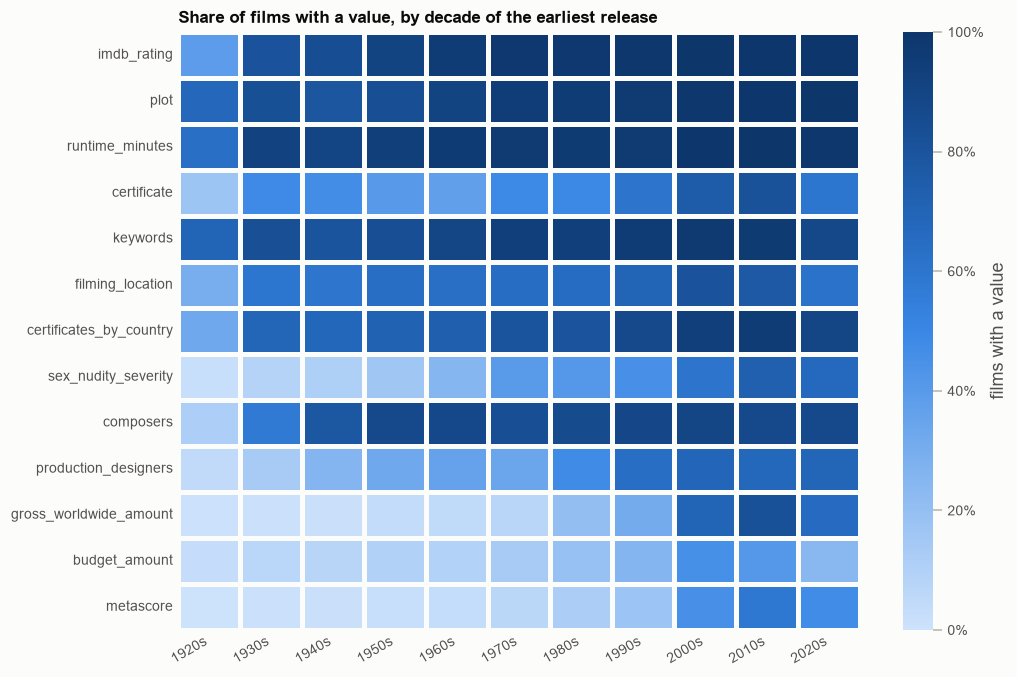

In [25]:
FIELDS_BY_DECADE = ["imdb_rating", "plot", "runtime_minutes", "certificate", "keywords", "filming_location",
                    "certificates_by_country", "sex_nudity_severity", "composers", "production_designers",
                    "gross_worldwide_amount", "budget_amount", "metascore"]
decade = (pd.to_numeric(movies["release_date"].str[:4]) // 10 * 10).rename("decade")
coverage = movies[FIELDS_BY_DECADE].notna().groupby(decade).mean().mul(100).T
coverage.columns = [f"{int(d)}s" for d in coverage.columns]
heatmap(coverage, "Share of films with a value, by decade of the earliest release", BLUES, "films with a value",
        percent=True, vmin=0, vmax=100)

## 7. Export

- **Parquet** keeps every type, including the nested lists and records.
- **CSV** writes lists as JSON arrays and each record as a JSON array of its fields, in the order the dictionary gives.
- **The data dictionary** describes every column.

A last check reads both files back.

In [26]:
DESCRIPTIONS = {
    "imdb_id": "IMDb title ID (tt followed by digits); one row per film.",
    "title": "Title shown on IMDb.",
    "original_title": "Title in its original language.",
    "release_date": "Earliest known release, ISO text at its own precision (YYYY, YYYY-MM or YYYY-MM-DD); IMDb's release year when no release date is known.",
    "release_date_precision": "Precision of release_date: year, month or day.",
    "release_country": "Country of the earliest known release; missing when only the release year is known.",
    "runtime_minutes": "Runtime in minutes.",
    "plot": "Plot outline; some are cut off with '...' on IMDb.",
    "poster_url": "URL of the film's main image on IMDb.",
    "genres": "IMDb genres.",
    "interests": "IMDb interests (sub-genres, themes and franchises), without the genre and language names that repeat genres and languages.",
    "keywords": "The first plot keywords IMDb shows (up to 5; see keywords_total).",
    "keywords_total": "Number of plot keywords IMDb holds for the film.",
    "countries_of_origin": "Countries of origin, with historical names as IMDb gives them (for example West Germany).",
    "languages": "Spoken languages; silent_movie for films without spoken language.",
    "production_companies": "Production companies.",
    "filming_location": "First filming location IMDb lists (see filming_locations_total).",
    "filming_locations_total": "Number of filming locations IMDb holds for the film.",
    "imdb_rating": "IMDb weighted user rating, 1 to 10; missing when the film has no votes.",
    "imdb_votes": "Number of user ratings; 0 when the film has none.",
    "rating_histogram": "Votes for each rating from 1 to 10.",
    "metascore": "Metacritic Metascore, 0 to 100.",
    "top_rated_rank": "Position in IMDb's Top Rated list.",
    "user_reviews_count": "Number of user reviews.",
    "critic_reviews_count": "Number of critic reviews.",
    "certificate": "US certificate as IMDb labels it (PG-13, Approved, TV-MA, ...), filled from US theatrical ratings when the title page had none.",
    "age_group": "Audience group of the certificate: general, parental_guidance, teen, mature, adults_only, approved (Production Code clearance, no age) or unrated.",
    "min_age": "Minimum age of the age group (0, 7, 13, 17 or 18); missing for approved and unrated.",
    **{column: f"Severity of {column.removesuffix('_severity').replace('_', ' ')} in IMDb's parental guide: none < mild < moderate < severe."
       for column in SEVERITY_COLUMNS},
    "certificates_by_country": "Certificates from IMDb's parental guide, one record per country rating (IMDb shows the first 50).",
    "certificates_total": "Number of countries with a certificate according to IMDb.",
    "budget_amount": "Production budget, in budget_currency (not converted).",
    "budget_currency": "ISO 4217 code of the budget's currency.",
    "gross_us_canada_amount": "Lifetime gross in the US and Canada, in gross_us_canada_currency.",
    "gross_us_canada_currency": "ISO 4217 code of the US and Canada gross (almost always USD).",
    "gross_worldwide_amount": "Lifetime worldwide gross, in gross_worldwide_currency.",
    "gross_worldwide_currency": "ISO 4217 code of the worldwide gross (almost always USD).",
    "opening_weekend_us_canada_usd": "Opening-weekend gross in the US and Canada, in USD.",
    "opening_weekend_end_date": "Last day of the opening weekend.",
    "award_wins": "Total award wins; 0 when IMDb lists none.",
    "award_nominations": "Award nominations that did not result in a win; 0 when IMDb lists none.",
    "prestigious_award_name": "The award IMDb singles out for the film (Oscar, BAFTA Film Award, ...).",
    "prestigious_award_wins": "Wins of that award; 0 when IMDb singles out none.",
    "prestigious_award_nominations": "Nominations for that award; 0 when IMDb singles out none.",
    **{group: f"{group.replace('_', ' ').capitalize()}, in the order of IMDb's full credits." for group in CREDIT_GROUPS},
    "cast": "Cast in the order of IMDb's full credits, with the characters each person played.",
    "similar_movies": "IMDb's 'More like this' films, in IMDb's order.",
    "release_dates": "Every release on IMDb: country, ISO date (possibly partial) and note.",
    "akas": "Alternative titles: country, title and note.",
}


def type_name(column):
    if column in FIELDS:
        fields = ", ".join(FIELDS[column])
        return f"list of {{{fields}}}; CSV: list of [{fields}]"
    if column in NESTED:
        return "list of integers" if column == "rating_histogram" else "list of text"
    dtype = movies[column].dtype
    if isinstance(dtype, pd.CategoricalDtype) and dtype.ordered:
        return "ordered category: " + " < ".join(dtype.categories)
    return str(dtype)


dictionary = pd.DataFrame({"column": COLUMNS, "type": [type_name(c) for c in COLUMNS],
                           "description": [DESCRIPTIONS[c] for c in COLUMNS]})
stem = OUTPUT_DIR / "imdb_movies_1920_2026_clean"
as_text = movies.copy()
for column in NESTED:
    as_text[column] = ARRAYS.get(column, movies[column]).map(lambda value: json.dumps(value, ensure_ascii=False), na_action="ignore")
as_text.to_csv(f"{stem}.csv", index=False, lineterminator="\n")
movies.to_parquet(f"{stem}.parquet", index=False)
dictionary.to_csv(f"{stem}_dictionary.csv", index=False)
del as_text

from_parquet = pd.read_parquet(f"{stem}.parquet")
from_csv = pd.read_csv(f"{stem}.csv", dtype=str, keep_default_na=False, na_values=[""])
assert from_parquet.shape == from_csv.shape == movies.shape
pd.testing.assert_frame_equal(from_parquet[SCALAR], movies[SCALAR], check_dtype=False)
assert all(from_csv[c].map(json.loads, na_action="ignore").equals(ARRAYS.get(c, movies[c])) for c in NESTED)
types_kept = (from_parquet[SCALAR].dtypes.astype(str) == movies[SCALAR].dtypes.astype(str)).all()
print(f"Both files read back with {len(movies):,} films x {movies.shape[1]} columns; Parquet types kept: {types_kept}.")
for suffix in (".parquet", ".csv", "_dictionary.csv"):
    print(f"  {Path(f'{stem}{suffix}').name}: {Path(f'{stem}{suffix}').stat().st_size / 1e6:,.1f} MB")
with pd.option_context("display.max_rows", 70, "display.max_colwidth", 110):
    display(dictionary)

Both files read back with 106,905 films x 61 columns; Parquet types kept: True.
  imdb_movies_1920_2026_clean.parquet: 170.5 MB
  imdb_movies_1920_2026_clean.csv: 500.7 MB
  imdb_movies_1920_2026_clean_dictionary.csv: 0.0 MB


,column,type,description
0,imdb_id,string,IMDb title ID (tt followed by digits); one row per film.
1,title,string,Title shown on IMDb.
2,original_title,string,Title in its original language.
3,release_date,string,"Earliest known release, ISO text at its own precision (YYYY, YYYY-MM or YYYY-MM-DD); IMDb's release year w..."
4,release_date_precision,category,"Precision of release_date: year, month or day."
5,release_country,category,Country of the earliest known release; missing when only the release year is known.
6,runtime_minutes,Int32,Runtime in minutes.
7,plot,string,Plot outline; some are cut off with '...' on IMDb.
8,poster_url,string,URL of the film's main image on IMDb.
9,genres,list of text,IMDb genres.


## Using the clean data

```python
import json
import re
import unicodedata
import pandas as pd

# Parquet: types kept, records are dicts
movies = pd.read_parquet("imdb_movies_1920_2026_clean.parquet")

# CSV: read as text, then turn the JSON arrays you need into lists or records
movies = pd.read_csv("imdb_movies_1920_2026_clean.csv", keep_default_na=False, na_values=[""], low_memory=False)
movies["directors"] = movies["directors"].map(
    lambda text: [dict(zip(["id", "name"], person)) for person in json.loads(text)], na_action="ignore")


def search_key(title):
    """A key for matching titles: compatibility forms folded, accents removed, lowercase, no punctuation."""
    text = unicodedata.normalize("NFKD", unicodedata.normalize("NFKC", title))
    text = "".join(ch for ch in text if not unicodedata.combining(ch)).casefold()
    return " ".join(re.sub(r"\W+", " ", text).split())
```

The data dictionary, `imdb_movies_1920_2026_clean_dictionary.csv`, gives every column's type, description and, for records, the order of the fields in the CSV.